# 유클리드 거리 vs DTW vs 대역 제한 DTW — 알고리즘 동작 GIF
- 위에서부터 순서대로 실행하면 `gifs/` 폴더에 GIF 4개와 단계별 캡처 PNG 4장이 저장되고, 각 셀 아래에 GIF가 재생됩니다.
- 입력: A = [1, 2, 5, 6, 4, 2, 1, 0, 0] (기준 동작), B = [0, 0, 1, 2, 5, 6, 4, 2, 1] (2프레임 늦은 같은 동작)
- ① 유클리드 선형 탐색 ② DTW 표 채우기 ③ 역추적 ④ 제약 없는 DTW vs 대역 제한 DTW

In [1]:
!pip install -q koreanize-matplotlib

### [0] 환경 설정

In [2]:
import os, sys, io
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
try:
    import koreanize_matplotlib  # noqa: F401  (한글 폰트)
except ImportError:
    pass
plt.rcParams["font.family"] = ["NanumGothic", "DejaVu Sans"]   # 한글 폰트에 없는 기호(−, √ 등)는 DejaVu Sans로 표시
plt.rcParams["axes.unicode_minus"] = False
os.makedirs("gifs", exist_ok=True)
INF = float("inf")

COL_A, COL_B = "#2a78d6", "#eb6834"           # A = 파랑, B = 주황
COL_HL, COL_NB = "#e34948", "#eda100"          # 현재 칸 = 빨강, 참조하는 이웃 = 노랑
COL_GRID, COL_TXT2, COL_SKIP = "#d9d8d4", "#52514e", "#e6e5e1"
IN_NOTEBOOK = "ipykernel" in sys.modules

### [1] 입력 데이터와 핵심 알고리즘

In [3]:
A = [1, 2, 5, 6, 4, 2, 1, 0, 0]     # 기준 동작
B = [0, 0, 1, 2, 5, 6, 4, 2, 1]     # 같은 동작, 2프레임 늦게 시작
N = len(A)
R_BAND = 2                          # 대역 제한 DTW의 밴드 폭

def euclidean_steps(a, b):
    """선형 탐색: i번째끼리만 비교하며 누적합을 기록"""
    s, steps = 0, []
    for i in range(len(a)):
        d = (a[i] - b[i]) ** 2
        s += d
        steps.append((i, d, s))
    return steps

def dtw_table(a, b, r=None):
    """DTW 누적 비용 표 D와 칸을 채운 순서. r이 있으면 |i-j| <= r 인 칸만 계산"""
    n, m = len(a), len(b)
    D = np.full((n + 1, m + 1), INF)
    D[0, 0] = 0.0
    order = []
    for i in range(1, n + 1):
        lo, hi = (1, m) if r is None else (max(1, i - r), min(m, i + r))
        for j in range(lo, hi + 1):
            cost = (a[i - 1] - b[j - 1]) ** 2
            D[i, j] = cost + min(D[i - 1, j - 1], D[i - 1, j], D[i, j - 1])
            order.append((i, j))
    return D, order

def backtrack(D):
    """(n,m)에서 (1,1)까지 ↖ ↑ ← 중 가장 작은 칸으로 거꾸로 이동 (같으면 ↖ 우선)"""
    i, j = D.shape[0] - 1, D.shape[1] - 1
    path = [(i, j)]
    while (i, j) != (1, 1):
        cands = [(D[i - 1, j - 1], i - 1, j - 1), (D[i - 1, j], i - 1, j), (D[i, j - 1], i, j - 1)]
        _, i, j = min(cands, key=lambda t: t[0])
        path.append((i, j))
    return path            # (n,m)부터 (1,1)까지의 순서

D_FULL, ORDER_FULL = dtw_table(A, B)
D_BAND, ORDER_BAND = dtw_table(A, B, R_BAND)
PATH_BT = backtrack(D_FULL)                     # 역추적 순서
print("유클리드 거리 =", round(euclidean_steps(A, B)[-1][2] ** 0.5, 2),
      "/ DTW 거리 =", round(D_FULL[-1, -1] ** 0.5, 2),
      f"/ 대역 제한 DTW(r={R_BAND}) 거리 =", round(D_BAND[-1, -1] ** 0.5, 2))

유클리드 거리 = 8.25 / DTW 거리 = 2.0 / 대역 제한 DTW(r=2) 거리 = 2.0


### [2] 그리기 도우미

In [4]:
def fmt(v):
    return "∞" if np.isinf(v) else f"{int(v)}"

def draw_table(ax, D, filled, cur=None, path=(), band=None, vmax=90, show_vals=True, title=""):
    """행 = A, 열 = B. filled: 계산이 끝난 칸, cur: 지금 계산/확인하는 칸, path: 빨간 테두리 칸"""
    cmap = plt.get_cmap("Blues")
    for i in range(N + 1):
        for j in range(N + 1):
            if band is not None and i > 0 and j > 0 and abs(i - j) > band:
                face, txt, tc = COL_SKIP, "", COL_TXT2
            elif i == 0 or j == 0:
                face, txt, tc = "#f5f4f1", ("0" if i == j == 0 else "∞"), COL_TXT2
            elif (i, j) in filled:
                v = D[i, j]
                face = cmap(0.08 + 0.75 * min(v, vmax) / vmax)
                txt, tc = (fmt(v) if show_vals else ""), ("white" if v / vmax > 0.5 else "#0b0b0b")
            else:
                face, txt, tc = "white", "", "#0b0b0b"
            ax.add_patch(patches.Rectangle((j, i), 1, 1, facecolor=face, edgecolor=COL_GRID, lw=1))
            if txt:
                ax.text(j + 0.5, i + 0.5, txt, ha="center", va="center", fontsize=9, color=tc)
    for (i, j) in path:
        ax.add_patch(patches.Rectangle((j, i), 1, 1, fill=False, edgecolor=COL_HL, lw=2.4))
    if cur is not None:
        i, j = cur
        for (pi, pj) in [(i - 1, j - 1), (i - 1, j), (i, j - 1)]:
            ax.add_patch(patches.Rectangle((pj, pi), 1, 1, fill=False, edgecolor=COL_NB, lw=2.6))
            ax.annotate("", xy=(j + 0.5, i + 0.5), xytext=(pj + 0.5, pi + 0.5),
                        arrowprops=dict(arrowstyle="->", color=COL_NB, lw=2, shrinkA=7, shrinkB=13))
        ax.add_patch(patches.Rectangle((j, i), 1, 1, fill=False, edgecolor=COL_HL, lw=3.4))
    ax.set_xlim(0, N + 1); ax.set_ylim(N + 1, 0)
    ax.set_xticks([j + 0.5 for j in range(N + 1)])
    ax.set_xticklabels(["–"] + [f"b{j}\n({B[j-1]})" for j in range(1, N + 1)], fontsize=8)
    ax.set_yticks([i + 0.5 for i in range(N + 1)])
    ax.set_yticklabels(["–"] + [f"a{i} ({A[i-1]})" for i in range(1, N + 1)], fontsize=8)
    ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_aspect("equal")
    ax.set_title(title, fontsize=12)

def draw_pair(ax, pairs, hl=None, title="", gap=8):
    """A(위)와 B(아래)를 그리고, pairs의 (i, j)끼리 선으로 잇는다 (0부터 시작하는 번호)"""
    x = np.arange(N)
    ax.plot(x, A, "-o", color=COL_A, lw=2, ms=7, label="A (기준 동작)", zorder=3)
    ax.plot(x, np.array(B) - gap, "-o", color=COL_B, lw=2, ms=7, label="B (2프레임 늦은 같은 동작)", zorder=3)
    for k, (i, j) in enumerate(pairs):
        on = hl is not None and k == hl
        ax.plot([i, j], [A[i], B[j] - gap], "-", color=COL_HL if on else "#8f8e89", lw=2.4 if on else 1.2, zorder=2)
        if on:
            ax.scatter([i, j], [A[i], B[j] - gap], s=160, facecolors="none", edgecolors=COL_HL, lw=2, zorder=4)
    ax.set_xticks(x); ax.set_xticklabels(x + 1); ax.set_yticks([])
    for s in ["top", "right", "left"]:
        ax.spines[s].set_visible(False)
    ax.set_xlabel("시간(프레임)")
    ax.set_ylim(-gap - 1, 7.5)
    ax.set_title(title, fontsize=12)

def caption(fig, text, y=0.02):
    fig.text(0.5, y, text, ha="center", va="bottom", fontsize=12,
             bbox=dict(boxstyle="round,pad=0.5", fc="#f7f6f3", ec=COL_GRID))

def to_image(fig, dpi=90):
    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=dpi, facecolor="white")
    plt.close(fig)
    buf.seek(0)
    return Image.open(buf).convert("RGB")

def save_gif(frames, durations, name):
    """frames: PIL 이미지 목록, durations: 각 프레임을 보여줄 시간(ms)"""
    path = f"gifs/{name}.gif"
    frames[0].save(path, save_all=True, append_images=frames[1:], duration=durations, loop=0, optimize=True)
    print(f"saved: {path}  ({len(frames)}프레임, {os.path.getsize(path)/1024:.0f}KB)")
    if IN_NOTEBOOK:
        from IPython.display import Image as IPImage, display
        display(IPImage(filename=path))

def save_keyframes(frames, idx, labels, name, cols=2):
    """보고서용 단계별 캡처: GIF에서 몇 장면을 골라 한 장으로 모은다"""
    rows = (len(idx) + cols - 1) // cols
    fig, axs = plt.subplots(rows, cols, figsize=(7 * cols, 0.62 * 7 * rows * frames[0].height / frames[0].width * 1.6))
    for ax, k, lab in zip(np.ravel(axs), idx, labels):
        ax.imshow(frames[k]); ax.axis("off"); ax.set_title(lab, fontsize=12, fontweight="bold")
    for ax in np.ravel(axs)[len(idx):]:
        ax.axis("off")
    fig.tight_layout()
    fig.savefig(f"gifs/{name}.png", dpi=150, facecolor="white", bbox_inches="tight")
    plt.close(fig)
    print(f"saved: gifs/{name}.png")

### [3] GIF ① 유클리드 거리 — 선형 탐색

saved: gifs/gif1_euclidean.gif  (11프레임, 107KB)


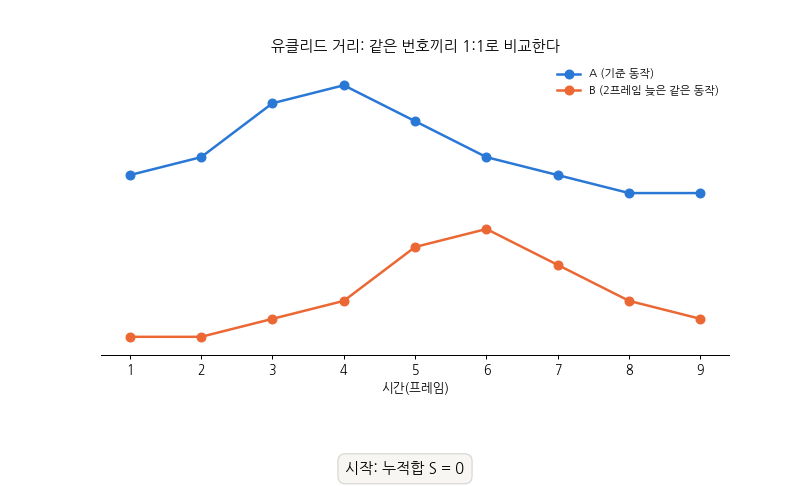

saved: gifs/gif1_keyframes.png


In [5]:
steps = euclidean_steps(A, B)
frames, durs = [], []
fig, ax = plt.subplots(figsize=(9, 5.4)); fig.subplots_adjust(bottom=0.27, top=0.88)
draw_pair(ax, [], title="유클리드 거리: 같은 번호끼리 1:1로 비교한다")
ax.legend(loc="upper right", frameon=False, fontsize=9)
caption(fig, "시작: 누적합 S = 0")
frames.append(to_image(fig)); durs.append(1500)
for k, (i, d, s) in enumerate(steps):
    fig, ax = plt.subplots(figsize=(9, 5.4)); fig.subplots_adjust(bottom=0.27, top=0.88)
    draw_pair(ax, [(t, t) for t in range(i + 1)], hl=i, title=f"유클리드 거리 — Step {i+1} / {N}")
    ax.legend(loc="upper right", frameon=False, fontsize=9)
    caption(fig, f"a{i+1}과 b{i+1}만 비교:  ({A[i]} − {B[i]})² = {d}   →   누적 S = {s}")
    frames.append(to_image(fig)); durs.append(1300)
fig, ax = plt.subplots(figsize=(9, 5.4)); fig.subplots_adjust(bottom=0.27, top=0.88)
draw_pair(ax, [(t, t) for t in range(N)], title="유클리드 거리 — 완료 (9번 비교)")
ax.legend(loc="upper right", frameon=False, fontsize=9)
S = steps[-1][2]
caption(fig, f"유클리드 거리 = √{S} = {S**0.5:.2f}   (봉우리가 서로 다른 시점에 있어 거리가 크다)")
frames.append(to_image(fig)); durs.append(3000)
save_gif(frames, durs, "gif1_euclidean")
GIF1 = frames
save_keyframes(GIF1, [1, 4, 6, 10], ["Step 1", "Step 4", "Step 6", "완료"], "gif1_keyframes")

### [4] GIF ② DTW — DP 테이블 채우기

saved: gifs/gif2_dtw_fill.gif  (83프레임, 1152KB)


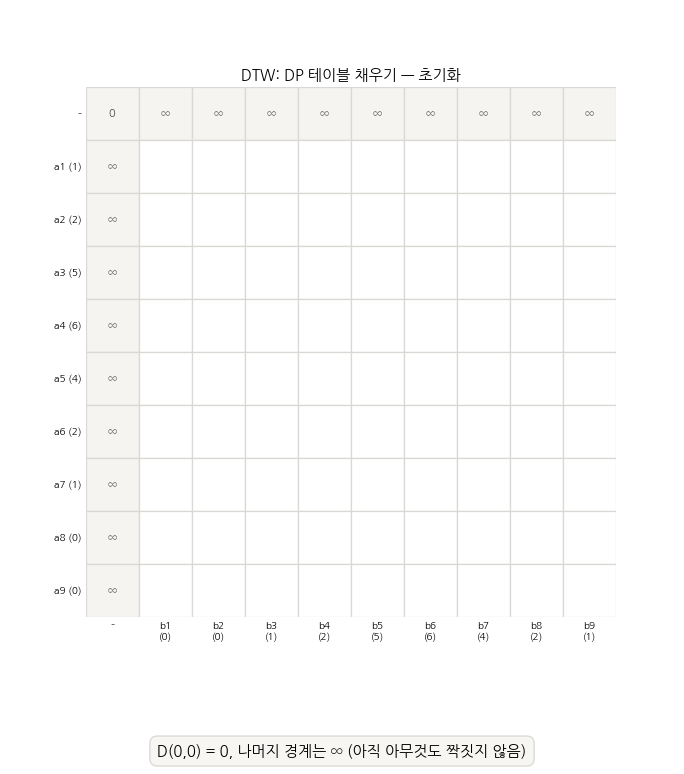

saved: gifs/gif2_keyframes.png


In [6]:
frames, durs = [], []
fig, ax = plt.subplots(figsize=(7.6, 8.6)); fig.subplots_adjust(bottom=0.16, top=0.93)
draw_table(ax, D_FULL, set(), title="DTW: DP 테이블 채우기 — 초기화")
caption(fig, "D(0,0) = 0, 나머지 경계는 ∞ (아직 아무것도 짝짓지 않음)")
frames.append(to_image(fig)); durs.append(1800)
for k, (i, j) in enumerate(ORDER_FULL):
    c = (A[i - 1] - B[j - 1]) ** 2
    nb = (D_FULL[i - 1, j - 1], D_FULL[i - 1, j], D_FULL[i, j - 1])
    fig, ax = plt.subplots(figsize=(7.6, 8.6)); fig.subplots_adjust(bottom=0.16, top=0.93)
    draw_table(ax, D_FULL, set(ORDER_FULL[:k + 1]), cur=(i, j), title=f"DTW: DP 테이블 채우기 — {k+1} / {N*N}칸")
    caption(fig, f"칸 ({i},{j}):  비용 ({A[i-1]} − {B[j-1]})² = {c}  +  min(↖ {fmt(nb[0])}, ↑ {fmt(nb[1])}, ← {fmt(nb[2])})"
                 f"  =  {fmt(D_FULL[i, j])}")
    frames.append(to_image(fig)); durs.append(700 if k < N else 280)   # 1행은 천천히
fig, ax = plt.subplots(figsize=(7.6, 8.6)); fig.subplots_adjust(bottom=0.16, top=0.93)
draw_table(ax, D_FULL, set(ORDER_FULL), title="DTW: DP 테이블 완성")
caption(fig, f"오른쪽 아래 D(9,9) = {fmt(D_FULL[-1,-1])}  →  DTW 거리 = √{fmt(D_FULL[-1,-1])} = {D_FULL[-1,-1]**0.5:.2f}")
frames.append(to_image(fig)); durs.append(3000)
save_gif(frames, durs, "gif2_dtw_fill")
GIF2 = frames
k46 = ORDER_FULL.index((4, 6)) + 1
save_keyframes(GIF2, [0, 2, k46, len(frames) - 1], ["초기화", "칸 (1,2)", "칸 (4,6)", "완성"], "gif2_keyframes")

### [5] GIF ③ DTW — 역추적으로 워핑 경로 찾기

saved: gifs/gif3_backtrack.gif  (12프레임, 288KB)


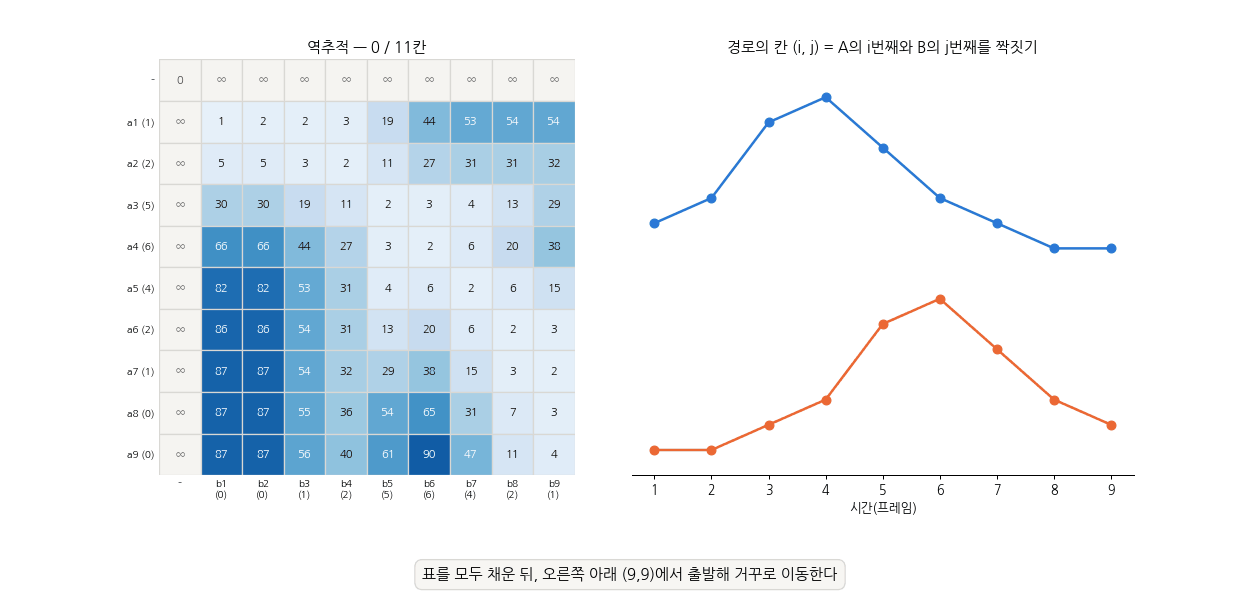

saved: gifs/gif3_keyframes.png


In [7]:
frames, durs = [], []
done = set(ORDER_FULL)
for k in range(len(PATH_BT) + 1):
    fig, axs = plt.subplots(1, 2, figsize=(14, 6.6), gridspec_kw={"width_ratios": [1, 1.2]})
    fig.subplots_adjust(bottom=0.2, top=0.9, wspace=0.12)
    shown = PATH_BT[:k]
    cur = PATH_BT[k - 1] if k else None
    draw_table(axs[0], D_FULL, done, path=shown, title=f"역추적 — {k} / {len(PATH_BT)}칸")
    if cur:
        axs[0].add_patch(patches.Rectangle((cur[1], cur[0]), 1, 1, fill=False, edgecolor=COL_HL, lw=4))
    draw_pair(axs[1], [(i - 1, j - 1) for i, j in shown], hl=(k - 1 if k else None),
              title="경로의 칸 (i, j) = A의 i번째와 B의 j번째를 짝짓기")
    if k == 0:
        caption(fig, "표를 모두 채운 뒤, 오른쪽 아래 (9,9)에서 출발해 거꾸로 이동한다")
        durs.append(1800)
    elif k < len(PATH_BT):
        i, j = cur; ni, nj = PATH_BT[k]
        arrow = "↖" if (ni, nj) == (i - 1, j - 1) else ("↑" if (ni, nj) == (i - 1, j) else "←")
        nbv = (D_FULL[i - 1, j - 1], D_FULL[i - 1, j], D_FULL[i, j - 1])
        caption(fig, f"({i},{j}) = {fmt(D_FULL[i,j])}:  ↖ {fmt(nbv[0])}, ↑ {fmt(nbv[1])}, ← {fmt(nbv[2])} 중 가장 작은 {arrow} 로 이동"
                     f"   |   a{i}({A[i-1]}) ↔ b{j}({B[j-1]})")
        durs.append(1300)
    else:
        caption(fig, "(1,1) 도착 — 경로 11칸 완성. 봉우리 a4와 b6처럼 모양이 같은 점끼리 짝지어졌다")
        durs.append(3500)
    frames.append(to_image(fig))
save_gif(frames, durs, "gif3_backtrack")
GIF3 = frames
save_keyframes(GIF3, [1, 3, 7, len(frames) - 1], ["1번째: (9,9)", "3번째: (7,9)", "7번째: (3,5)", "완료"],
               "gif3_keyframes", cols=1)

### [6] GIF ④ 제약 없는 DTW vs 대역 제한 DTW — 같은 속도로 동시에 채우기

saved: gifs/gif4_full_vs_band.gif  (82프레임, 1580KB)


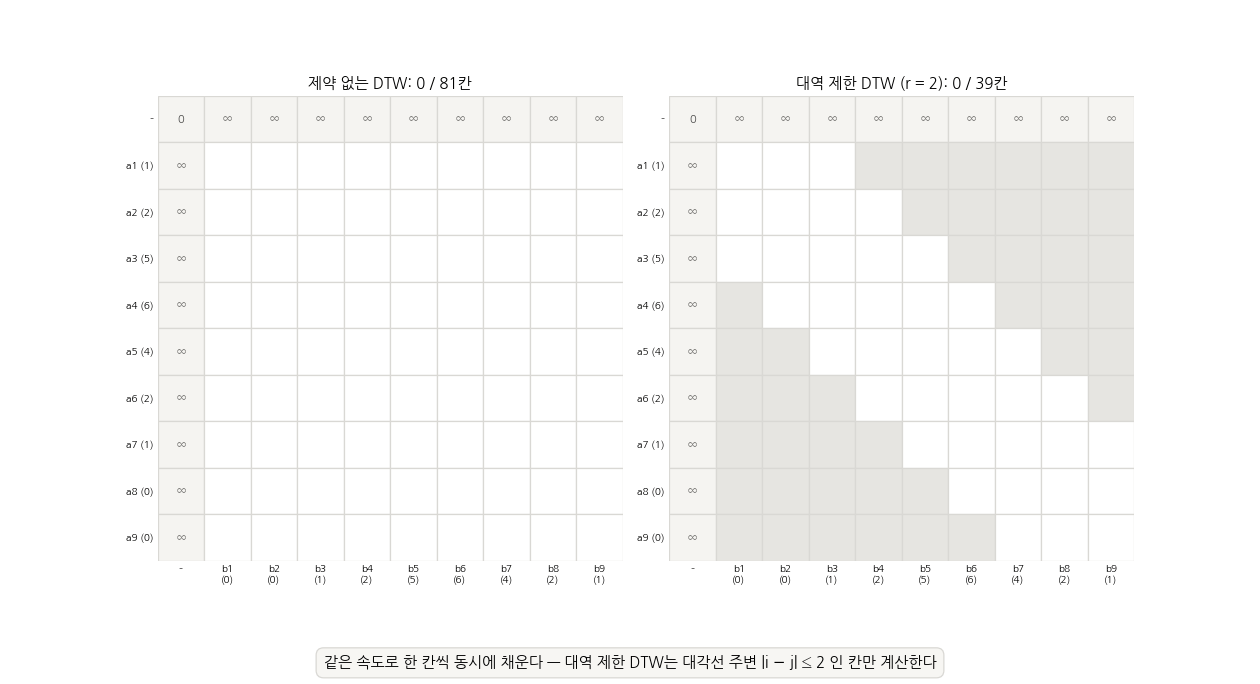

saved: gifs/gif4_keyframes.png


In [8]:
frames, durs = [], []
T = len(ORDER_FULL)
for k in range(T + 1):
    fig, axs = plt.subplots(1, 2, figsize=(14, 7.6)); fig.subplots_adjust(bottom=0.14, top=0.9, wspace=0.1)
    kf, kb = min(k, T), min(k, len(ORDER_BAND))
    pf = set(PATH_BT) if k == T else ()
    pb = set(backtrack(D_BAND)) if kb == len(ORDER_BAND) else ()
    draw_table(axs[0], D_FULL, set(ORDER_FULL[:kf]), path=pf,
               title=f"제약 없는 DTW: {kf} / {T}칸" + (f"  → 거리 {D_FULL[-1,-1]**0.5:.2f}" if k == T else ""))
    done_b = kb == len(ORDER_BAND)
    draw_table(axs[1], D_BAND, set(ORDER_BAND[:kb]), band=R_BAND, path=pb,
               title=f"대역 제한 DTW (r = {R_BAND}): {kb} / {len(ORDER_BAND)}칸"
                     + (f"  → 거리 {D_BAND[-1,-1]**0.5:.2f} (계산 끝)" if done_b else ""))
    if k == T:
        caption(fig, f"같은 답(거리 {D_BAND[-1,-1]**0.5:.2f})을 대역 제한 DTW는 {len(ORDER_BAND)}칸, 제약 없는 DTW는 {T}칸 계산으로 얻었다")
    else:
        caption(fig, "같은 속도로 한 칸씩 동시에 채운다 — 대역 제한 DTW는 대각선 주변 |i − j| ≤ 2 인 칸만 계산한다")
    frames.append(to_image(fig))
    durs.append(3500 if k == T else (1000 if k == 0 else 160))
save_gif(frames, durs, "gif4_full_vs_band")
GIF4 = frames
save_keyframes(GIF4, [20, len(ORDER_BAND), 60, T], ["20칸째", f"{len(ORDER_BAND)}칸째: 대역 제한 DTW 완료", "60칸째", f"{T}칸째: 둘 다 완료"],
               "gif4_keyframes", cols=1)

### 결과 내려받기 (Colab 전용)
`gifs` 폴더를 압축해서 내 컴퓨터로 내려받습니다.

In [9]:
import shutil, sys
shutil.make_archive("gifs", "zip", "gifs")      # gifs.zip 만들기
if "google.colab" in sys.modules:
    from google.colab import files
    files.download("gifs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>